# Data Merge and Product Recommendation Model

This notebook prepares the customer data and trains a model to predict the product category a customer is likely to buy.

## 1. Load the datasets

We load the customer profiles and transaction tables into pandas DataFrames.

In [6]:
import pandas as pd

profiles = pd.read_csv("../data/raw/customer_social_profiles.csv")
transactions = pd.read_csv("../data/raw/customer_transactions.csv")

## 2. Inspect the profiles table

We check the table's size, first rows, data types, missing values, duplicate rows, and number of unique values in each column.

In [8]:
print("Rows and columns:", profiles.shape)
print(profiles.head())
print(profiles.dtypes)
print("Missing values:\n", profiles.isna().sum())
print("Duplicate rows:", profiles.duplicated().sum())
print("Unique values:\n", profiles.nunique())

Rows and columns: (155, 5)
  customer_id_new social_media_platform  engagement_score  \
0            A178              LinkedIn                74   
1            A190               Twitter                82   
2            A150              Facebook                96   
3            A162               Twitter                89   
4            A197               Twitter                92   

   purchase_interest_score review_sentiment  
0                      4.9         Positive  
1                      4.8          Neutral  
2                      1.6         Positive  
3                      2.6         Positive  
4                      2.3          Neutral  
customer_id_new             object
social_media_platform       object
engagement_score             int64
purchase_interest_score    float64
review_sentiment            object
dtype: object
Missing values:
 customer_id_new            0
social_media_platform      0
engagement_score           0
purchase_interest_score    0
review_s

## 3. Inspect the transactions table

We run the same checks here and see how often each product category appears.

In [9]:
print("Rows and columns:", transactions.shape)
print(transactions.head())
print(transactions.dtypes)
print("Missing values:\n", transactions.isna().sum())
print("Duplicate rows:", transactions.duplicated().sum())
print("Unique values:\n", transactions.nunique())
print(transactions["product_category"].value_counts())

Rows and columns: (150, 6)
   customer_id_legacy  transaction_id  purchase_amount purchase_date  \
0                 151            1001              408    2024-01-01   
1                 192            1002              332    2024-01-02   
2                 114            1003              442    2024-01-03   
3                 171            1004              256    2024-01-04   
4                 160            1005               64    2024-01-05   

  product_category  customer_rating  
0           Sports              2.3  
1      Electronics              4.2  
2      Electronics              2.1  
3         Clothing              2.8  
4         Clothing              1.3  
customer_id_legacy      int64
transaction_id          int64
purchase_amount         int64
purchase_date          object
product_category       object
customer_rating       float64
dtype: object
Missing values:
 customer_id_legacy     0
transaction_id         0
purchase_amount        0
purchase_date          0
p

**Findings from the inspection:**
- The profiles table has 155 rows, including 5 fully duplicated rows.
- It contains 84 unique customers, so some customers have several profile rows.
- The transactions table has 150 purchases from 75 unique customers.
- The two tables use different customer ID formats (`A178` and `151`), so we need to test whether they match.
- `product_category` is the target and has 5 fairly balanced classes.

## 4. Clean the profiles table

We remove the fully duplicated rows. Each customer can still have several different profile rows, which we will handle before merging.

In [10]:
profiles_clean = profiles.drop_duplicates().copy()

print("Rows before cleaning:", len(profiles))
print("Rows after cleaning:", len(profiles_clean))

print("Duplicate rows left:", profiles_clean.duplicated().sum())


Rows before cleaning: 155
Rows after cleaning: 150
Duplicate rows left: 0


## 5. Clean the transactions table

We convert `purchase_date` from text to a date. We also fill missing `customer_rating` values with the median, because the median is less affected by extreme values.



In [11]:
transactions_clean = transactions.copy()

transactions_clean["purchase_date"] = pd.to_datetime(transactions_clean["purchase_date"])

median_rating = transactions_clean["customer_rating"].median()
transactions_clean["customer_rating"] = transactions_clean["customer_rating"].fillna(median_rating)

print("Median rating used:", median_rating)
print("Missing ratings left:", transactions_clean["customer_rating"].isna().sum())
print("Purchase date type:", transactions_clean["purchase_date"].dtype)

Median rating used: 3.0
Missing ratings left: 0
Purchase date type: datetime64[ns]


## 6. Match the customer IDs

The tables use different ID formats, such as `A178` and `151`. We assume that the number after "A" is the same customer ID, so we create a matching column and check how many customers appear in both tables.

In [12]:
print("All IDs follow the pattern:", profiles_clean["customer_id_new"].str.fullmatch(r"A\d+").all())

profiles_clean["customer_id_legacy"] = (
    profiles_clean["customer_id_new"].str.replace("A", "", regex=False).astype(int)
)

profile_ids = set(profiles_clean["customer_id_legacy"])
transaction_ids = set(transactions_clean["customer_id_legacy"])

print("Customers in both tables:", len(profile_ids & transaction_ids))
print("Customers only in profiles:", len(profile_ids - transaction_ids))
print("Customers only in transactions:", len(transaction_ids - profile_ids))

All IDs follow the pattern: True
Customers in both tables: 61
Customers only in profiles: 23
Customers only in transactions: 14


**ID match findings:** All profile IDs follow the expected format. 61 customers appear in both tables, 23 appear only in profiles, and 14 appear only in transactions. The ID match is an assumption based on the shared numbers, so we report it as a limitation.

## 7. Combine each customer's profile rows

Some customers have several profile rows. Merging them directly would repeat purchases, so we create one row per customer. We average the numeric scores and keep the most common platform and sentiment. If there is a tie, pandas keeps the first value alphabetically.

In [13]:

profiles_by_customer = profiles_clean.groupby("customer_id_legacy").agg(
    engagement_score=("engagement_score", "mean"),
    purchase_interest_score=("purchase_interest_score", "mean"),
    social_media_platform=("social_media_platform", lambda x: x.mode()[0]),
    review_sentiment=("review_sentiment", lambda x: x.mode()[0]),
    profile_count=("customer_id_new", "size")
).reset_index()

print("Rows:", len(profiles_by_customer))
print("Unique customers:", profiles_by_customer["customer_id_legacy"].nunique())
print(profiles_by_customer.head())

Rows: 84
Unique customers: 84
   customer_id_legacy  engagement_score  purchase_interest_score  \
0                 100         77.000000                 4.400000   
1                 101         68.000000                 1.000000   
2                 102         51.000000                 4.800000   
3                 103         64.333333                 2.866667   
4                 104         83.000000                 2.933333   

  social_media_platform review_sentiment  profile_count  
0             Instagram         Negative              2  
1               Twitter          Neutral              1  
2              LinkedIn          Neutral              1  
3             Instagram         Positive              3  
4               Twitter         Negative              3  


## 8. Merge the tables

We use an inner merge on `customer_id_legacy`, keeping purchases only when the customer also has profile data. This avoids inventing profile details for customers without one, though it means we lose some transactions.

In [14]:
merged = transactions_clean.merge(
    profiles_by_customer,
    on="customer_id_legacy",
    how="inner",
    validate="many_to_one"
)

print("Transactions before merge:", len(transactions_clean))
print("Rows after merge:", len(merged))
print("Transactions removed:", len(transactions_clean) - len(merged))
print("Unique customers:", merged["customer_id_legacy"].nunique())
print("Duplicate transaction IDs:", merged["transaction_id"].duplicated().sum())
print("Missing values:\n", merged.isna().sum())
print(merged["product_category"].value_counts())
print(merged.head())

Transactions before merge: 150
Rows after merge: 117
Transactions removed: 33
Unique customers: 61
Duplicate transaction IDs: 0
Missing values:
 customer_id_legacy         0
transaction_id             0
purchase_amount            0
purchase_date              0
product_category           0
customer_rating            0
engagement_score           0
purchase_interest_score    0
social_media_platform      0
review_sentiment           0
profile_count              0
dtype: int64
product_category
Sports         28
Electronics    27
Clothing       22
Groceries      20
Books          20
Name: count, dtype: int64
   customer_id_legacy  transaction_id  purchase_amount purchase_date  \
0                 151            1001              408    2024-01-01   
1                 192            1002              332    2024-01-02   
2                 114            1003              442    2024-01-03   
3                 160            1005               64    2024-01-05   
4                 120         

**Merge validation:** The inner merge kept 117 of the 150 transactions and removed 33 (22%) from customers without profile data. The result has 61 customers, no duplicate transaction IDs, and no missing values. All 5 product categories remain, with 20 to 28 rows each.

## 9. Exploratory data analysis

We first review the variable types and summary statistics. We then use plots to examine distributions, outliers, and relationships between numeric variables.

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

numeric_columns = [
    "purchase_amount",
    "customer_rating",
    "engagement_score",
    "purchase_interest_score"
]

print(merged.dtypes)
print(merged[numeric_columns].describe().round(2))

customer_id_legacy                  int64
transaction_id                      int64
purchase_amount                     int64
purchase_date              datetime64[ns]
product_category                   object
customer_rating                   float64
engagement_score                  float64
purchase_interest_score           float64
social_media_platform              object
review_sentiment                   object
profile_count                       int64
dtype: object
       purchase_amount  customer_rating  engagement_score  \
count           117.00           117.00            117.00   
mean            287.91             3.11             74.15   
std             120.08             1.20             12.67   
min              62.00             1.00             50.00   
25%             183.00             2.10             66.50   
50%             280.00             3.20             77.00   
75%             397.00             4.10             83.00   
max             495.00             5

**Summary statistics:** Purchase amounts range from 62 to 495, with a median of 280. Customer ratings range from 1 to 5, engagement scores from 50 to 99, and purchase interest scores from 1 to 4.8. These ranges look reasonable, and there are no missing values in these columns.

### Distribution of product categories

This plot shows how many purchases fall into each product category, which is the value our model will predict.

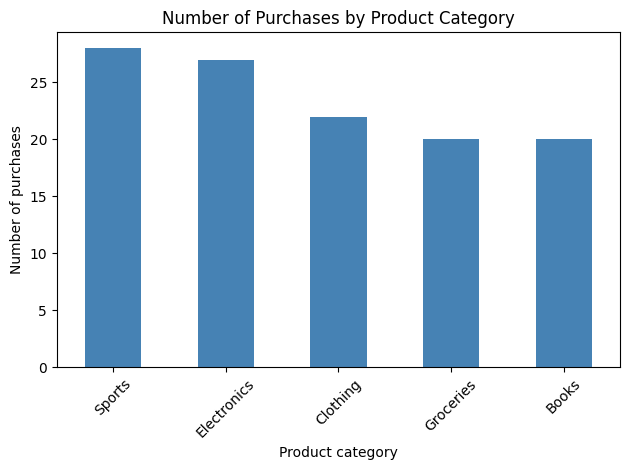

In [16]:
merged["product_category"].value_counts().plot(kind="bar", color="steelblue")
plt.title("Number of Purchases by Product Category")
plt.xlabel("Product category")
plt.ylabel("Number of purchases")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Finding:** The classes are fairly balanced, from 20 purchases for Books and Groceries to 28 for Sports. No category dominates, but each has only a small number of examples for training.

### Distribution of purchase amounts

This histogram shows the common purchase amounts and how widely they vary.

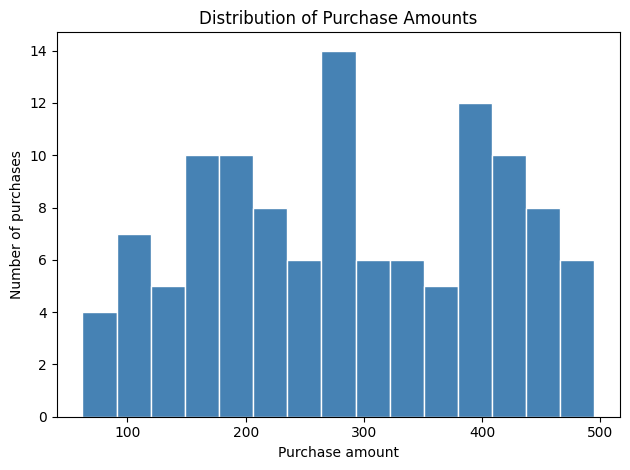

In [17]:
plt.hist(merged["purchase_amount"], bins=15, color="steelblue", edgecolor="white")
plt.title("Distribution of Purchase Amounts")
plt.xlabel("Purchase amount")
plt.ylabel("Number of purchases")
plt.tight_layout()
plt.show()

**Finding:** Purchase amounts range from about 60 to 500 and are spread widely, with no single clear peak. The histogram shows more purchases around 280 and 400, but with only 117 rows these bumps may be partly due to chance.

### Outlier check

Box plots show the spread of each numeric variable. Points beyond the whiskers are possible outliers.

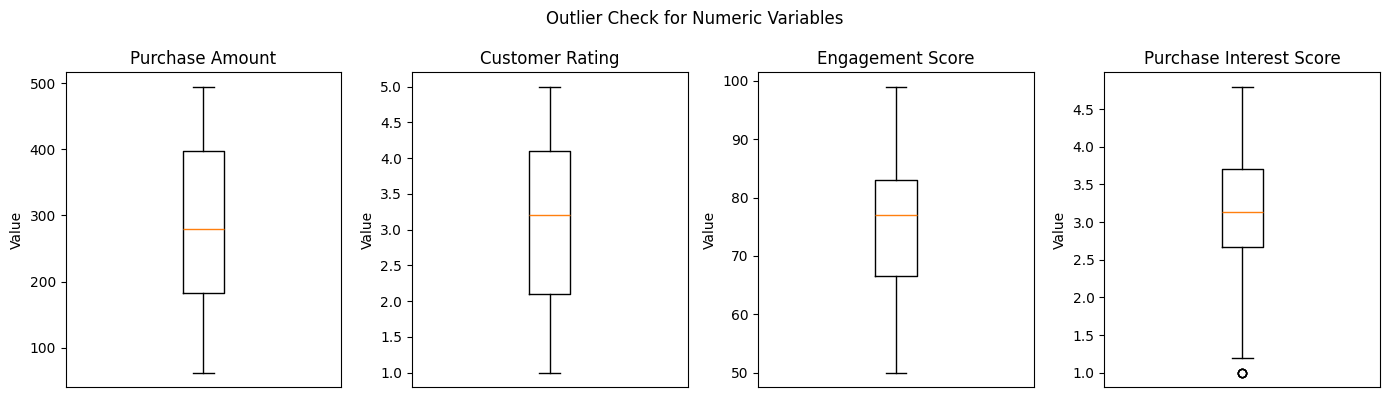

In [18]:
fig, axes = plt.subplots(1, 4, figsize=(14, 4))

for axis, column in zip(axes, numeric_columns):
    axis.boxplot(merged[column])
    axis.set_title(column.replace("_", " ").title())
    axis.set_ylabel("Value")
    axis.set_xticks([])

fig.suptitle("Outlier Check for Numeric Variables")
plt.tight_layout()
plt.show()

**Finding:** The only possible outlier is a purchase interest score of about 1.0. It looks like a valid low score rather than an error, so we keep it. The other numeric variables show no points beyond the whiskers.

### Correlation between numeric variables

The heatmap shows how strongly pairs of numeric variables move together, from -1 to 1. Values near 0 suggest little linear relationship.

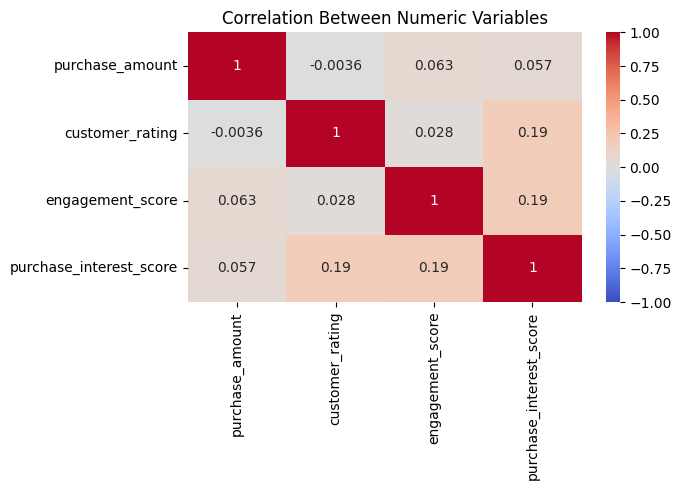

In [19]:
correlations = merged[numeric_columns].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(correlations, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Between Numeric Variables")
plt.tight_layout()
plt.show()

**Finding:** All correlations between these numeric variables are weak. The strongest are 0.19, between purchase interest and both customer rating and engagement. They show little linear overlap, but this does not tell us how well they predict product category.

## 10. Feature engineering

We create features from each customer's earlier purchases and their social media activity. Earlier-purchase features use only past transactions, so they do not reveal information from the purchase being predicted. For a customer's first purchase, these averages are set to 0 and `previous_purchases` is also 0.

In [20]:
features = merged.sort_values(
    ["customer_id_legacy", "purchase_date", "transaction_id"]
).copy()

customer_groups = features.groupby("customer_id_legacy")

features["previous_purchases"] = customer_groups.cumcount()

features["avg_previous_amount"] = customer_groups["purchase_amount"].transform(
    lambda values: values.shift().expanding().mean()
).fillna(0)

features["avg_previous_rating"] = customer_groups["customer_rating"].transform(
    lambda values: values.shift().expanding().mean()
).fillna(0)

features["engagement_interest"] = (
    features["engagement_score"] * features["purchase_interest_score"]
)

features["purchase_month"] = features["purchase_date"].dt.month

print("Rows and columns:", features.shape)
print("Missing values:", features.isna().sum().sum())
print(features[[
    "customer_id_legacy",
    "purchase_date",
    "purchase_amount",
    "previous_purchases",
    "avg_previous_amount",
    "avg_previous_rating",
    "engagement_interest",
    "purchase_month"
]].head(8))

Rows and columns: (117, 16)
Missing values: 0
     customer_id_legacy purchase_date  purchase_amount  previous_purchases  \
87                  100    2024-04-22              172                   0   
113                 100    2024-05-26              387                   1   
14                  101    2024-01-17              271                   0   
18                  101    2024-01-21              192                   1   
47                  101    2024-02-28              408                   2   
58                  101    2024-03-13              145                   3   
11                  102    2024-01-14              101                   0   
35                  102    2024-02-14              380                   1   

     avg_previous_amount  avg_previous_rating  engagement_interest  \
87              0.000000             0.000000                338.8   
113           172.000000             4.000000                338.8   
14              0.000000             0.00

## 11. Save the merged dataset

We save the merged data with its engineered features to `data/processed/merged_dataset.csv` so it can be included in the GitHub repository.

In [24]:
features.to_csv("../data/processed/merged_dataset.csv", index=False)
print("Saved merged_dataset.csv with shape:", features.shape)

Saved merged_dataset.csv with shape: (117, 16)


## 12. Prepare the data for modelling

The model predicts `product_category`. We use social media data and the customer's earlier purchase history. We exclude IDs and raw dates, along with the current purchase amount and rating, because those are not known before the purchase. We keep 20% of the rows as a test set.

In [25]:
from sklearn.model_selection import train_test_split

numeric_features = [
    "engagement_score",
    "purchase_interest_score",
    "profile_count",
    "previous_purchases",
    "avg_previous_amount",
    "avg_previous_rating",
    "engagement_interest",
    "purchase_month"
]
categorical_features = ["social_media_platform", "review_sentiment"]

X = features[numeric_features + categorical_features]
y = features["product_category"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

Training rows: 93
Test rows: 24


## 13. Train the product recommendation model

We use a Random Forest because it can capture non-linear patterns. The pipeline converts text columns to numbers and then trains the model, so new data can be prepared the same way.

In [26]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

preprocessor = ColumnTransformer(
    [("categories", OneHotEncoder(handle_unknown="ignore"), categorical_features)],
    remainder="passthrough"
)

product_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", RandomForestClassifier(n_estimators=300, random_state=42))
])

product_model.fit(X_train, y_train)
print("Model trained")

Model trained


## 14. Evaluate the model

We report accuracy, macro F1-score, and log loss on the test set. We compare them with a baseline that ignores the inputs: it always predicts the most common category and gives each category its share of the training data as a probability. We also use 5-fold cross-validation because a test set this small can give unstable results.

In [27]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, classification_report, f1_score, log_loss
from sklearn.model_selection import StratifiedKFold, cross_val_score

predictions = product_model.predict(X_test)
probabilities = product_model.predict_proba(X_test)

baseline = DummyClassifier(strategy="prior")
baseline.fit(X_train, y_train)
baseline_predictions = baseline.predict(X_test)
baseline_probabilities = baseline.predict_proba(X_test)

print("MODEL")
print("Accuracy:", round(accuracy_score(y_test, predictions), 3))
print("Macro F1:", round(f1_score(y_test, predictions, average="macro", zero_division=0), 3))
print("Log loss:", round(log_loss(y_test, probabilities, labels=product_model.classes_), 3))

print("\nBASELINE")
print("Accuracy:", round(accuracy_score(y_test, baseline_predictions), 3))
print("Macro F1:", round(f1_score(y_test, baseline_predictions, average="macro", zero_division=0), 3))
print("Log loss:", round(log_loss(y_test, baseline_probabilities, labels=baseline.classes_), 3))

folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(product_model, X, y, cv=folds, scoring="f1_macro")
print("\nCross-validated macro F1:", round(scores.mean(), 3), "+/-", round(scores.std(), 3))

print("\n", classification_report(y_test, predictions, zero_division=0))

MODEL
Accuracy: 0.208
Macro F1: 0.175
Log loss: 1.908

BASELINE
Accuracy: 0.25
Macro F1: 0.08
Log loss: 1.593

Cross-validated macro F1: 0.246 +/- 0.09

               precision    recall  f1-score   support

       Books       0.00      0.00      0.00         4
    Clothing       0.50      0.50      0.50         4
 Electronics       0.30      0.50      0.38         6
   Groceries       0.00      0.00      0.00         4
      Sports       0.00      0.00      0.00         6

    accuracy                           0.21        24
   macro avg       0.16      0.20      0.17        24
weighted avg       0.16      0.21      0.18        24



## 15. Compare candidate models

The first model performed close to chance and was overconfident. We compare simpler models with cross-validation on the training data only. This limits overfitting to the test set, although we have already seen the first model's test results.

In [28]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate
from sklearn.preprocessing import StandardScaler

scaled_preprocessor = ColumnTransformer([
    ("numbers", StandardScaler(), numeric_features),
    ("categories", OneHotEncoder(handle_unknown="ignore"), categorical_features)
])

candidates = {
    "Baseline": DummyClassifier(strategy="prior"),
    "Random Forest": Pipeline([
        ("preprocessing", preprocessor),
        ("classifier", RandomForestClassifier(n_estimators=300, random_state=42))
    ]),
    "Simpler Random Forest": Pipeline([
        ("preprocessing", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=300, max_depth=3, min_samples_leaf=5, random_state=42
        ))
    ]),
    "Logistic Regression": Pipeline([
        ("preprocessing", scaled_preprocessor),
        ("classifier", LogisticRegression(max_iter=1000))
    ])
}

results = []

for name, candidate in candidates.items():
    scores = cross_validate(
        candidate, X_train, y_train, cv=folds,
        scoring=["accuracy", "f1_macro", "neg_log_loss"]
    )
    results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Macro F1": scores["test_f1_macro"].mean(),
        "Log loss": -scores["test_neg_log_loss"].mean()
    })

print(pd.DataFrame(results).round(3).to_string(index=False))

                Model  Accuracy  Macro F1  Log loss
             Baseline     0.215     0.071     1.604
        Random Forest     0.302     0.264     1.677
Simpler Random Forest     0.312     0.246     1.574
  Logistic Regression     0.280     0.246     1.816


**Model comparison:** We choose the Simpler Random Forest. In cross-validation on the training data, it had the highest accuracy (0.312) and the lowest log loss (1.574). It was the only candidate to beat the baseline's log loss (1.604). Limiting tree depth and leaf size may also reduce overconfidence, which matters with so few rows.

## 16. Final model evaluation

We train the chosen model on all the training data and evaluate it on the test set. The test set is small and was also used to evaluate the first model, so these results are only a rough estimate.

In [29]:
final_model = candidates["Simpler Random Forest"]
final_model.fit(X_train, y_train)

final_predictions = final_model.predict(X_test)
final_probabilities = final_model.predict_proba(X_test)

print("Accuracy:", round(accuracy_score(y_test, final_predictions), 3))
print("Macro F1:", round(f1_score(y_test, final_predictions, average="macro", zero_division=0), 3))
print("Log loss:", round(log_loss(y_test, final_probabilities, labels=final_model.classes_), 3))
print("\n", classification_report(y_test, final_predictions, zero_division=0))

Accuracy: 0.25
Macro F1: 0.173
Log loss: 1.617

               precision    recall  f1-score   support

       Books       0.00      0.00      0.00         4
    Clothing       0.25      0.50      0.33         4
 Electronics       0.44      0.67      0.53         6
   Groceries       0.00      0.00      0.00         4
      Sports       0.00      0.00      0.00         6

    accuracy                           0.25        24
   macro avg       0.14      0.23      0.17        24
weighted avg       0.15      0.25      0.19        24



## 17. Save the model

We save the full pipeline, including the text encoding step, to `models/product_model.pkl` so it can be used in the command-line app. We then test that the saved model loads and makes a prediction.

In [30]:
import joblib
import sklearn

model_path = "../models/product_model.pkl"

joblib.dump(final_model, model_path)

loaded_model = joblib.load(model_path)
example_customer = X_test.iloc[[0]]

print("Saved model to:", model_path)
print("Example input:")
print(example_customer)
print("Predicted product:", loaded_model.predict(example_customer)[0])
print("Input columns:", list(X.columns))
print("scikit-learn version:", sklearn.__version__)

Saved model to: ../models/product_model.pkl
Example input:
    engagement_score  purchase_interest_score  profile_count  \
43              50.0                      3.6              1   

    previous_purchases  avg_previous_amount  avg_previous_rating  \
43                   1                292.0                  1.2   

    engagement_interest  purchase_month social_media_platform review_sentiment  
43                180.0               2                TikTok         Positive  
Predicted product: Electronics
Input columns: ['engagement_score', 'purchase_interest_score', 'profile_count', 'previous_purchases', 'avg_previous_amount', 'avg_previous_rating', 'engagement_interest', 'purchase_month', 'social_media_platform', 'review_sentiment']
scikit-learn version: 1.9.1


## 18. Final results and limitations

The final Simpler Random Forest achieved an accuracy of 0.250, a macro F1-score of 0.173, and a log loss of 1.617 on the test set. Its accuracy matched the baseline (0.250), and its log loss was slightly worse (baseline: 1.593). Its macro F1-score was higher than the baseline's (0.080), but only because the baseline predicts a single category. The model made no correct predictions for Books, Groceries, or Sports, so it should not be treated as reliable for real recommendations.

**Main limitations:**
- The merged dataset has only 117 rows across 5 categories, and the test set has only 24.
- The available inputs may contain little information about which product a customer will choose.
- The inner merge removed 33 transactions (22%) from customers without profile data.
- The ID match between `A178` and `178` is an assumption based on the shared numbers.
- The test set was used to evaluate both the first and final models, so its results are only a rough estimate.
- A random split can place the same customer in both training and test data, so results may not apply to new customers.

**Next steps:** Collect more data, gather features more closely linked to product choice, and test on customers the model has not seen.